# Task: Convolution and Deconvolution

**Student Name:** Sébastien Bagdasarianz  
**Country:** Colombia  
**Semester term:** HS26

## Day 11 – Data & Domain


### Use Case
*Focus: domain and application context*

<span style="background-color: #eeeeee;">*Guidelines: Describe a realistic application scenario in which the targeted signal processing task plays a critical role. Clearly specify the domain, the system in which the signal is measured or processed, and the practical objective of this system. Explain who relies on the signal and for what type of decision-making or analysis. Briefly explain why this use case is particularly relevant for your selected country. Write your use case as a short, focused paragraph (1-3 sentences).*</span>

In the context of passive acoustic biodiversity monitoring in Colombian tropical ecosystems, wildlife acoustic signals are acquired using autonomous recording units (AudioMoth) deployed in dense forest vegetation to monitor avian populations and detect ecological shifts. The practical objective is to capture distinct vocalization features of indicator bird species amidst pervasive environmental interference, providing clean audio for automated feature extraction, spectrogram segmentation, and taxonomic classification. This use case is particularly critical for Colombia because its dense Neotropical habitats generate high levels of acoustic interference—including torrential rain showers, wind-induced canopy rustling, river background, and high-frequency insect stridulations (cicadas)—which obscure diagnostic call formants and necessitate principled filtering and signal reconstruction to preserve ecological data integrity.


### Problem Statement
*Focus: technical vulnerability*

<span style="background-color: #eeeeee;">*Guidelines: Formulate a clear and technically precise problem statement. Explicitly refer to the signal processing task under investigation and identify the specific technical risk or limitation associated with it. Describe what may go wrong if an approach, method, or parameter is chosen or applied inadequately. Explain why this technical vulnerability is critical within your selected use case. Write your problem statement as a short, focused paragraph (1–3 sentences).*</span>

This project addresses the dual problem of applying one-dimensional spatial-domain convolution to suppress acoustic noise and subsequently evaluating deconvolution to restore attenuated vocalization features in Colombian avian bioacoustic data. In field deployments, raw bird recordings are frequently degraded by high-frequency insect noise ($>8\text{ kHz}$) and transient environmental fluctuations that mask the target vocalization structure; convolution with an appropriate smoothing or low-pass kernel can attenuate these disturbances and enhance the signal-to-noise ratio of core formants, but excessive smoothing blurs sharp syllable onset attacks and attenuates critical diagnostic upper harmonics. Conversely, deconvolution seeks to invert this blurring and restore the original sharp acoustic dynamics, but unconstrained or poorly regularized deconvolution is mathematically ill-posed, causing catastrophic noise amplification and instability in the presence of even modest recording noise. Balancing noise suppression during convolution against reconstruction stability and fidelity during deconvolution is essential for reliable bioacoustic signal enhancement in conservation applications.


### Experimental Objective
*Focus: investigation goal at the conceptual level.*

<span style="background-color: #eeeeee;">*Guidelines: Clearly state what you intend to understand or demonstrate in relation to your use case. Formulate your objective at a conceptual level without describing specific methods, algorithms, or implementation details. The objective should explain what aspect of signal behavior you aim to analyze and why this analysis is important for your application. Write your objective as a short, focused paragraph (1–2 sentences).*</span>

The objective of this project is to investigate how one-dimensional convolution in the spatial/time domain can suppress environmental noise while preserving characteristic avian vocalization features, and to examine how effectively deconvolution can reconstruct the original acoustic dynamics from the filtered signal. The goal is to determine the trade-offs between smoothing strength, feature preservation, noise amplification, and reconstruction fidelity in Colombian bioacoustic analysis.


### Data Definition, Source, and Visualization
*Focus: data characteristics, data source, and visual inspection.*

<span style="background-color: #eeeeee;">*Guidelines: Describe a representative one-dimensional signal suitable for your use case. Briefly explain its physical origin, how it is acquired, its unit of measurement, and the key characteristics relevant to your investigation. Specify the exact dataset name and repository or institution from which the data originate, and justify why this source is appropriate. Write 3-5 concise sentences.*</span>

The selected signal represents a representative 2.0-second bioacoustic vocalization excerpt of the Great Kiskadee (*Pitangus sulphuratus*), recorded in Pijavay, Magdalena, Colombia (Project `MAP1`, recording `P5-G022_04-13_tlapse.wav`, segment `segment-249-0029`). The signal represents normalized acoustic sound pressure amplitude in $[-1.0, 1.0]$, recorded using an autonomous AudioMoth v1.2 acoustic logger and sampled at 48 kHz ($f_s = 48\text{ kHz}$, 96,000 samples). Its relevant characteristics include sharp syllable onset transients (rise time $<20\text{ ms}$), steep frequency modulations ($1.5 - 2.2\text{ kHz}$ fundamental), and rich harmonic overtones spanning up to 12 kHz, accompanied by ambient tropical forest background noise. The data originate from the curated **PteroSet** dataset (Version 5, 2026; DOI: [10.5281/zenodo.21829388](https://doi.org/10.5281/zenodo.21829388)), published by Ruiz, Ulloa, Miao et al. in collaboration with the Microsoft AI for Good Lab and the Instituto Alexander von Humboldt. This data source is uniquely appropriate because it provides an authentic, high-quality field vocalization containing both sharp transient attacks (sensitive to smoothing distortion) and high-frequency harmonics (sensitive to attenuation and deconvolution noise amplification), establishing an ideal benchmark for convolution and deconvolution.


<span style="background-color: #eeeeee;">*Guideline: Visualize a representative excerpt of your signal. If the data are audio-based, additionally provide a playable audio segment. All visualizations must include clearly labeled axes and the correct units.*</span>


Dataset: PteroSet v5 (Zenodo: 10.5281/zenodo.21829388)
Location: Pijavay, Magdalena, Colombia (Project MAP1)
Species: Pitangus sulphuratus (Great Kiskadee / Bichofué)
Sampling Rate: 48,000 Hz (48 kHz)
Signal Duration: 2.00 s (96,000 samples)
Peak Normalized Amplitude: 0.2877 a.u.


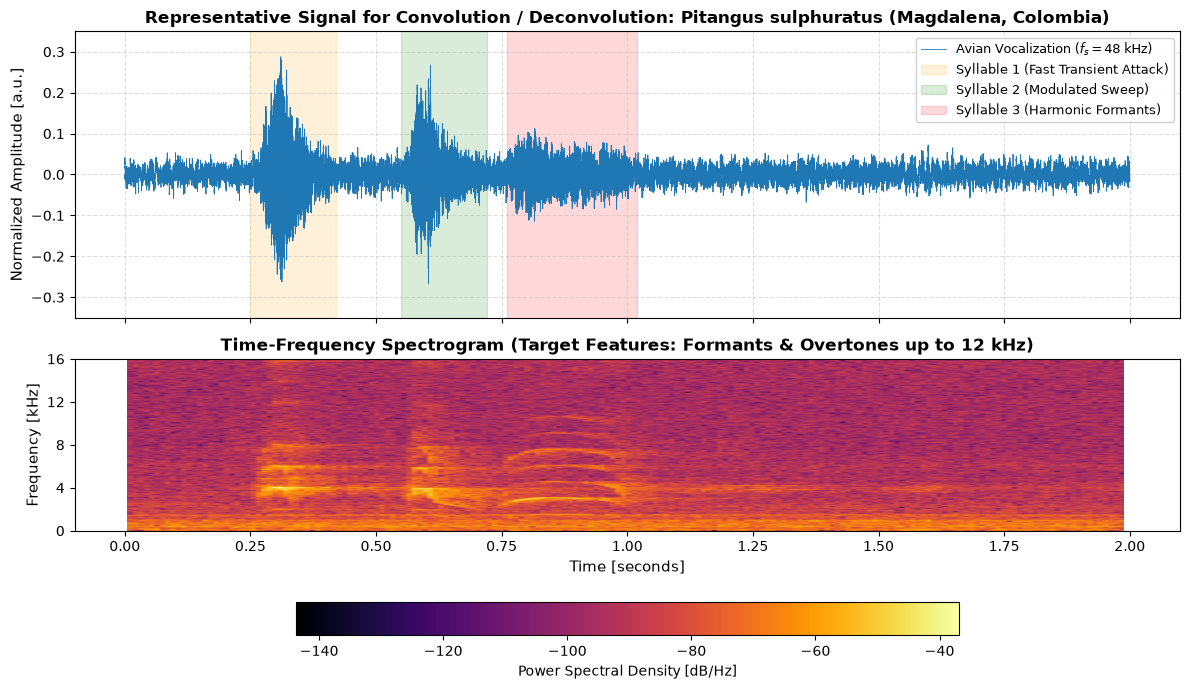

Playable Audio - Representative 2.0s Bioacoustic Vocalization:


In [3]:
import os
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
import IPython.display as ipd

# Path definitions
audio_dir = DATA_DIR
call_file = os.path.join(audio_dir, "call_template_2s_48khz.wav")

signal_2s, sr = sf.read(call_file)
time_2s = np.arange(len(signal_2s)) / sr

print(f"Dataset: PteroSet v5 (Zenodo: 10.5281/zenodo.21829388)")
print(f"Location: Pijavay, Magdalena, Colombia (Project MAP1)")
print(f"Species: Pitangus sulphuratus (Great Kiskadee / Bichofué)")
print(f"Sampling Rate: {sr:,} Hz (48 kHz)")
print(f"Signal Duration: {len(signal_2s)/sr:.2f} s ({len(signal_2s):,} samples)")
print(f"Peak Normalized Amplitude: {np.max(np.abs(signal_2s)):.4f} a.u.")

# ── Visualization: Clean Waveform & Spectrogram ───────────────────────────
fig, (ax_wave, ax_spec) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# 1. Waveform
ax_wave.plot(time_2s, signal_2s, color="#1f77b4", linewidth=0.6, label="Avian Vocalization ($f_s = 48$ kHz)")
ax_wave.set_ylabel("Normalized Amplitude [a.u.]", fontsize=11)
ax_wave.set_title("Representative Signal for Convolution / Deconvolution: Pitangus sulphuratus (Magdalena, Colombia)", fontsize=12, fontweight="bold")
ax_wave.grid(True, linestyle="--", alpha=0.4)
ax_wave.set_ylim(-0.35, 0.35)

# Highlight fast transients
ax_wave.axvspan(0.25, 0.42, color="orange", alpha=0.15, label="Syllable 1 (Fast Transient Attack)")
ax_wave.axvspan(0.55, 0.72, color="green", alpha=0.15, label="Syllable 2 (Modulated Sweep)")
ax_wave.axvspan(0.76, 1.02, color="red", alpha=0.15, label="Syllable 3 (Harmonic Formants)")
ax_wave.legend(loc="upper right", framealpha=0.9, fontsize=9)

# 2. Spectrogram
Pxx, freqs, bins, im = ax_spec.specgram(
    signal_2s, 
    NFFT=1024, 
    Fs=sr, 
    noverlap=512, 
    cmap="inferno"
)
ax_spec.set_ylabel("Frequency [kHz]", fontsize=11)
ax_spec.set_xlabel("Time [seconds]", fontsize=11)
ax_spec.set_ylim(0, 16000)
ax_spec.set_yticks(np.arange(0, 17000, 4000))
ax_spec.set_yticklabels([f"{f/1000:.0f}" for f in np.arange(0, 17000, 4000)])
ax_spec.set_title("Time-Frequency Spectrogram (Target Features: Formants & Overtones up to 12 kHz)", fontsize=12, fontweight="bold")

cbar = fig.colorbar(im, ax=ax_spec, orientation="horizontal", pad=0.25, shrink=0.6)
cbar.set_label("Power Spectral Density [dB/Hz]", fontsize=10)

plt.tight_layout()
plt.show()

# ── Playable Audio ────────────────────────────────────────────────────────
print("Playable Audio - Representative 2.0s Bioacoustic Vocalization:")
ipd.display(ipd.Audio(filename=str(DATA_DIR / "call_template_2s_48khz.wav")))


### Observations

> The visualization illustrates the acoustic waveform and time-frequency spectrogram of the representative 2.0-second vocalization excerpt of the Great Kiskadee (*Pitangus sulphuratus*), recorded at 48 kHz in Magdalena, Colombia.  
> In the time domain, the signal is characterized by three distinct acoustic syllables with sharp onset transients (rise time $<20\text{ ms}$) reaching a maximum amplitude of 0.288 a.u., interspersed with low-amplitude background noise ($\\le 0.04$ a.u.).  
> In the frequency domain, the target bird vocalization occupies a structured band from 1.5 kHz to 12 kHz, featuring a modulated fundamental frequency ($1.5 - 2.2\text{ kHz}$) and three prominent harmonic formants, flanked by background noise extending across the spectrum.  
> This excerpt was selected because its combination of steep onset transients and dense harmonic overtone bands provides a rigorous benchmark for testing both smoothing effectiveness and transient preservation during convolution, as well as stability and fidelity during deconvolution.


### Task-Specific Answers: Methodological Framing for Convolution and Deconvolution

#### 1. Expected Effect of Convolutional Filtering in Bioacoustics
* **Physical Objective:** In Colombian forest recordings, ambient environmental disturbances (wind turbulence, rain splatter, foliage noise, and high-frequency insect stridulations) corrupt the audio signal. Applying 1D convolution with a designed kernel $h[n]$ (e.g., Gaussian smoothing or low-pass FIR filter) performs a localized weighted moving average across the time domain:
  $$y[n] = (x * h)[n] = \sum_{k=-\infty}^{\infty} x[k] \cdot h[n-k]$$
* **Expected Signal Improvements:**
  - *Noise Attenuation:* Rapid stochastic fluctuations caused by uncorrelated environmental noise are suppressed, improving the effective signal-to-noise ratio (SNR) in the active vocalization band.
  - *Feature Enhancement:* Low-pass or bandpass convolution emphasizes the macroscopic energy envelope of vocalization syllables, making syllable segmentation and energy-based onset detection significantly more robust.
* **Inherent Trade-offs / Vulnerabilities:**
  - *Transient Blurring:* Avian vocal syllables feature steep attack slopes ($<20\text{ ms}$). Convolution smooths these sharp transitions, reducing temporal localization accuracy.
  - *Harmonic Attenuation:* Excessive smoothing attenuates high-frequency formants (6–12 kHz), potentially distorting relative harmonic ratios essential for species determination.

#### 2. The Role of Deconvolution as an Inverse Operation
* **Inverse Problem Formulation:** Deconvolution aims to invert the transformation introduced by convolution. If an observed or filtered signal $y[n]$ is the result of convolving the original signal $x[n]$ with an impulse response or smoothing kernel $h[n]$ in the presence of noise $w[n]$:
  $$y[n] = (x * h)[n] + w[n]$$
  In the frequency domain:
  $$Y(f) = X(f) \cdot H(f) + W(f)$$
  The goal of deconvolution is to estimate $\hat{x}[n] \approx x[n]$ by applying an inverse filter $g[n]$:
  $$\hat{X}(f) = Y(f) \cdot G(f)$$
* **Why Deconvolution is Relevant in Bioacoustics:**
  - *Restoring Attenuated Transients:* Deconvolution can sharpen blurred syllable onsets, recovering original temporal boundaries and acoustic rise times.
  - *Equalizing Channel Distortion:* In natural forest canopies, sound propagates through dense vegetation, branches, and leaves, which acts as a physical dispersive filter (foliage impulse response). Deconvolution offers a theoretical mechanism to compensate for physical channel reverberation.
* **Critical Challenges (Ill-Posedness & Noise Amplification):**
  - Direct inverse filtering ($G(f) = 1 / H(f)$) is highly ill-posed because smoothing kernels have frequency responses $H(f) \to 0$ at higher frequencies.
  - Dividing by near-zero values violently amplifies any residual noise $W(f) / H(f)$, causing numerical instability and catastrophic noise explosion.
  - Therefore, practical deconvolution requires **regularization** (e.g., regularized inverse filtering or Wiener deconvolution: $G(f) = \frac{H^*(f)}{|H(f)|^2 + \alpha}$), explicitly balancing reconstruction fidelity against noise amplification.
